# HAR Classification with tensorts

End-to-end Human Activity Recognition on the UCI HAR dataset, using **tensorts** for the full preprocessing pipeline and sklearn/PyTorch for classification.

This notebook mirrors `Lecture1_Classification_IoT_Temporal_Data.py` but replaces all manual preprocessing (windowing, scaling, feature extraction, label encoding) with tensorts transforms.

---
## 1. Setup and Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    f1_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.feature_selection import f_classif
from scipy.stats import gaussian_kde
import warnings
warnings.filterwarnings('ignore')

# tensorts imports
from tensorts import (
    TimeTensor, Dim, Pipeline,
    StandardScaler, LabelEncoder,
    SlidingWindow, Flatten, PCA,
    FunctionTransform, FeatureExtractor,
    ChannelTransform, SklearnWrapper,
    Scope, make_statistical_extractor,
)

# Plotting style
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

SEED = 42
np.random.seed(SEED)
print('Libraries loaded successfully.')

Libraries loaded successfully.


---
## 2. Download and Load UCI HAR Dataset

In [2]:
import os, urllib.request, zipfile

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00240/UCI%20HAR%20Dataset.zip"
ZIP_PATH = "UCI_HAR_Dataset.zip"
DATA_DIR = "UCI HAR Dataset"

if not os.path.exists(DATA_DIR):
    print("Downloading UCI HAR Dataset...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall('.')
    print("Done!")
else:
    print("Dataset already downloaded.")

Dataset already downloaded.


In [3]:
BASE = "UCI HAR Dataset"

# Activity labels
activity_labels = pd.read_csv(f"{BASE}/activity_labels.txt", sep=' ', header=None, names=['id', 'name'])
id2label = dict(zip(activity_labels['id'], activity_labels['name']))
print(f"Activities: {id2label}")

# Pre-extracted 561 features (for later comparison)
feature_names = pd.read_csv(f"{BASE}/features.txt", sep=r'\s+', header=None, names=['idx', 'name'])['name'].tolist()

# Labels and subjects
y_train_ids = pd.read_csv(f"{BASE}/train/y_train.txt", header=None)[0].values
y_test_ids  = pd.read_csv(f"{BASE}/test/y_test.txt",  header=None)[0].values
subj_train  = pd.read_csv(f"{BASE}/train/subject_train.txt", header=None)[0].values
subj_test   = pd.read_csv(f"{BASE}/test/subject_test.txt",  header=None)[0].values

y_train_labels = np.array([id2label[i] for i in y_train_ids])
y_test_labels  = np.array([id2label[i] for i in y_test_ids])

# Load raw inertial signals
CHANNEL_NAMES = [
    'body_acc_x', 'body_acc_y', 'body_acc_z',
    'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
]

def load_raw_signals(split='train'):
    data = {}
    for ch in CHANNEL_NAMES:
        path = f"{BASE}/{split}/Inertial Signals/{ch}_{split}.txt"
        data[ch] = pd.read_csv(path, sep=r'\s+', header=None).values
    return data

raw_train = load_raw_signals('train')
raw_test  = load_raw_signals('test')

print(f"\nRaw signal shape per channel (train): {raw_train['body_acc_x'].shape}")
print(f"Raw signal shape per channel (test):  {raw_test['body_acc_x'].shape}")
print(f"Window: 128 samples at 50 Hz = 2.56 seconds, 50% overlap")

Activities: {1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS', 4: 'SITTING', 5: 'STANDING', 6: 'LAYING'}

Raw signal shape per channel (train): (7352, 128)
Raw signal shape per channel (test):  (2947, 128)
Window: 128 samples at 50 Hz = 2.56 seconds, 50% overlap


---
## 3. Reconstruct Continuous Signals per Subject

The UCI HAR dataset provides pre-windowed data (128 samples, 50% overlap). We reconstruct the continuous per-subject signals so we can later re-window with tensorts' `SlidingWindow`.

In [4]:
def reconstruct_continuous(windows_array, stride=64):
    """Reconstruct continuous signal from overlapping windows by averaging overlaps."""
    n_windows, window_size = windows_array.shape
    total_len = stride * (n_windows - 1) + window_size
    sig = np.zeros(total_len)
    counts = np.zeros(total_len)
    for i in range(n_windows):
        start = i * stride
        sig[start:start + window_size] += windows_array[i]
        counts[start:start + window_size] += 1
    sig /= counts
    return sig


def reconstruct_per_subject(raw_signals_dict, subjects, labels, stride=64):
    """Reconstruct continuous signals per subject."""
    result = {}
    channels = list(raw_signals_dict.keys())
    for subj_id in np.unique(subjects):
        mask = subjects == subj_id
        n_windows = mask.sum()
        window_size = raw_signals_dict[channels[0]].shape[1]
        total_len = stride * (n_windows - 1) + window_size
        signals = {ch: reconstruct_continuous(raw_signals_dict[ch][mask], stride) for ch in channels}
        subj_labels = labels[mask]
        sample_labels = np.empty(total_len, dtype=object)
        for i in range(n_windows):
            start = i * stride
            if i == 0:
                sample_labels[:stride] = subj_labels[i]
            else:
                sample_labels[start:start + stride] = subj_labels[i]
        sample_labels[stride * (n_windows - 1):] = subj_labels[-1]
        result[subj_id] = {'signals': signals, 'labels': sample_labels}
    return result


print("Reconstructing continuous signals per subject...")
continuous_train = reconstruct_per_subject(raw_train, subj_train, y_train_labels, stride=64)
continuous_test  = reconstruct_per_subject(raw_test,  subj_test,  y_test_labels,  stride=64)

example_subj = list(continuous_train.keys())[0]
example_len = len(continuous_train[example_subj]['signals']['body_acc_x'])
print(f"\nExample: Subject {example_subj}")
print(f"  Reconstructed signal length: {example_len} samples ({example_len / 50:.1f}s)")
print(f"  Channels: {list(continuous_train[example_subj]['signals'].keys())}")

Reconstructing continuous signals per subject...

Example: Subject 1
  Reconstructed signal length: 22272 samples (445.4s)
  Channels: ['body_acc_x', 'body_acc_y', 'body_acc_z', 'body_gyro_x', 'body_gyro_y', 'body_gyro_z']


---
## 4. Visualize Reconstructed Continuous Signal

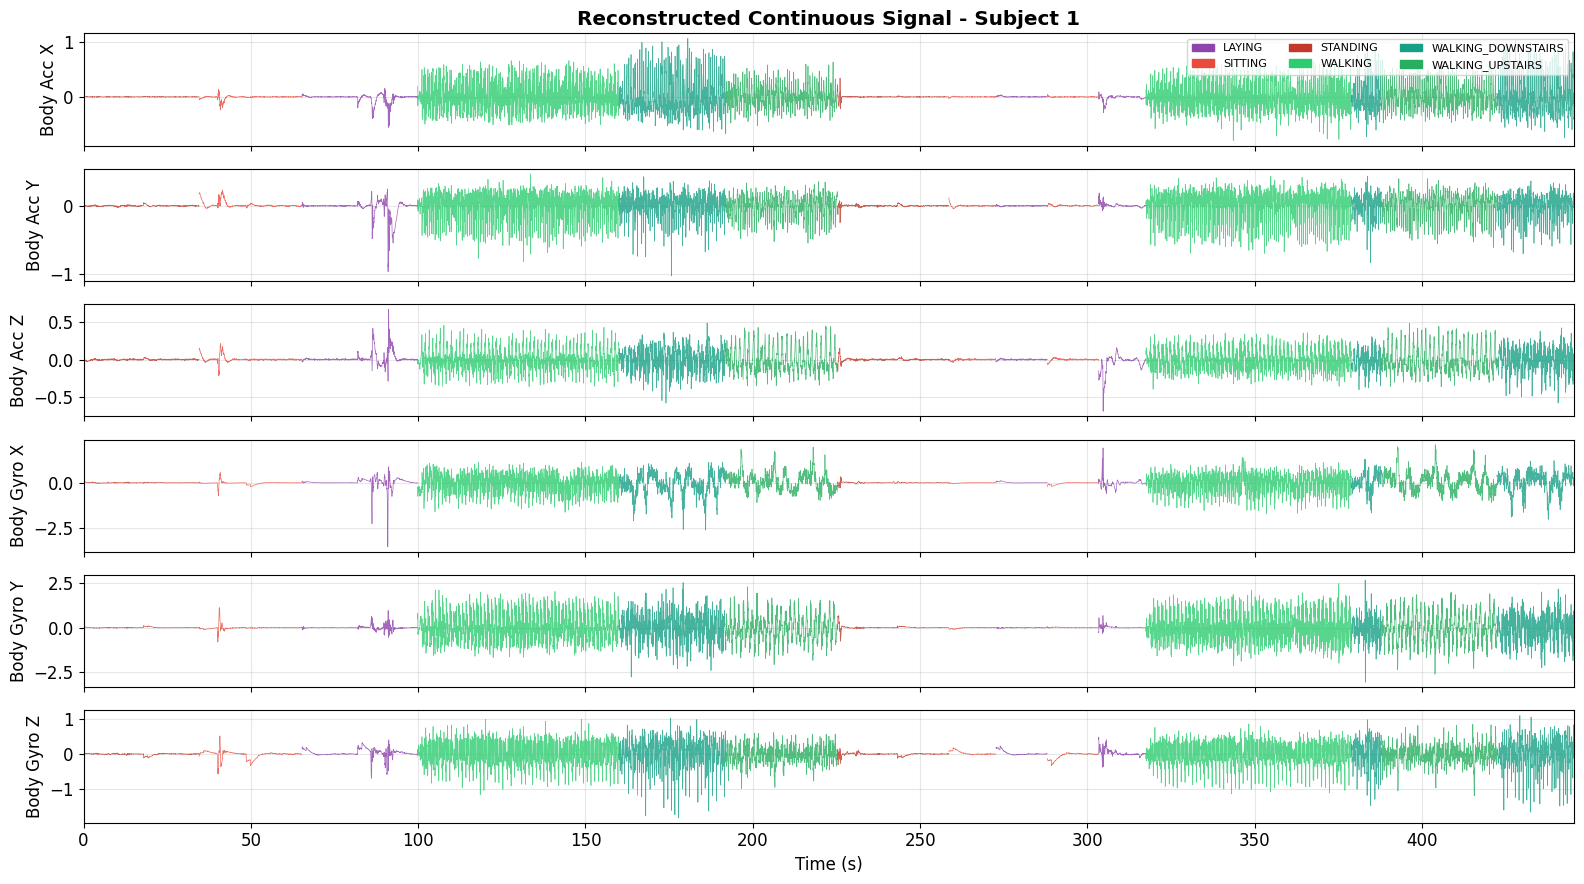

In [5]:
ACTIVITY_COLORS = {
    'WALKING':            '#2ecc71',
    'WALKING_UPSTAIRS':   '#27ae60',
    'WALKING_DOWNSTAIRS': '#16a085',
    'SITTING':            '#e74c3c',
    'STANDING':           '#c0392b',
    'LAYING':             '#8e44ad'
}

subj_id = list(continuous_train.keys())[0]
lab = continuous_train[subj_id]['labels']
t_cont = np.arange(len(lab)) / 50.0
unique_labels = np.unique(lab)

fig, axes = plt.subplots(len(CHANNEL_NAMES), 1, figsize=(16, 9), sharex=True)
for ax, ch in zip(axes, CHANNEL_NAMES):
    sig = continuous_train[subj_id]['signals'][ch]
    for act in unique_labels:
        act_mask = lab == act
        color = ACTIVITY_COLORS.get(act, '#999999')
        segments = np.where(np.diff(act_mask.astype(int)) != 0)[0] + 1
        segments = np.concatenate([[0], segments, [len(act_mask)]])
        for s, e in zip(segments[:-1], segments[1:]):
            if act_mask[s]:
                ax.plot(t_cont[s:e], sig[s:e], color=color, linewidth=0.5, alpha=0.8)
    ax.set_ylabel(ch.replace('_', ' ').title())
    ax.set_xlim(t_cont[0], t_cont[-1])

patches = [mpatches.Patch(color=ACTIVITY_COLORS[a], label=a) for a in unique_labels if a in ACTIVITY_COLORS]
axes[0].legend(handles=patches, loc='upper right', fontsize=8, ncol=3)
axes[0].set_title(f'Reconstructed Continuous Signal - Subject {subj_id}', fontweight='bold')
axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

---
## 5. Build Per-Subject TimeTensors (Ragged)

Each subject has a different recording length, so this is a natural fit for **ragged TimeTensors**. We stack each subject's 6-channel continuous signal into a `(T_i, 6)` array and build a ragged TimeTensor.

In [6]:
def build_subject_timetensor(continuous_data, majority_vote_stride=64):
    """Build a ragged TimeTensor from per-subject reconstructed signals.
    
    Each subject becomes one sample with shape (T_i, 6).
    Labels: one per subject (majority vote across all timesteps).
    """
    samples = []
    labels = []
    for subj_id in sorted(continuous_data.keys()):
        subj = continuous_data[subj_id]
        # Stack channels: (T_i, 6)
        sample = np.column_stack([subj['signals'][ch] for ch in CHANNEL_NAMES])
        samples.append(sample)
        # Each subject does multiple activities, so we store the full label sequence
        # and will let SlidingWindow + label_strategy handle per-window labels.
        # For now, use the majority label as a placeholder.
        vals, counts = np.unique(subj['labels'], return_counts=True)
        labels.append(vals[np.argmax(counts)])
    
    return samples, np.array(labels)


train_samples, _ = build_subject_timetensor(continuous_train)
test_samples, _  = build_subject_timetensor(continuous_test)

print(f"Train subjects: {len(train_samples)}")
print(f"Test subjects:  {len(test_samples)}")
print(f"Sample lengths (train): {[s.shape[0] for s in train_samples[:5]]}...")
print(f"Channels per sample: {train_samples[0].shape[1]}")

Train subjects: 21
Test subjects:  9
Sample lengths (train): [22272, 21888, 19392, 20864, 19776]...
Channels per sample: 6


---
## 6. Window Segmentation with Majority-Vote Labels

Since each subject performs multiple activities, we need per-window labels (not per-subject). We use the same segmentation as the original notebook but then load the result into tensorts `TimeTensor` for all downstream processing.

In [7]:
def sliding_window_segment(continuous_data, window_size, stride):
    """Apply sliding window to continuous per-subject data with majority-vote labels."""
    all_windows, all_labels, all_subjects = [], [], []
    for subj_id, subj_data in continuous_data.items():
        sig_len = len(subj_data['signals'][CHANNEL_NAMES[0]])
        labels_arr = subj_data['labels']
        for start in range(0, sig_len - window_size + 1, stride):
            end = start + window_size
            window = np.column_stack([subj_data['signals'][ch][start:end] for ch in CHANNEL_NAMES])
            all_windows.append(window)
            window_labels = labels_arr[start:end]
            vals, counts = np.unique(window_labels, return_counts=True)
            all_labels.append(vals[np.argmax(counts)])
            all_subjects.append(subj_id)
    return np.array(all_windows), np.array(all_labels), np.array(all_subjects)


WINDOW_SIZE = 128
STRIDE = 64

print(f"Window size: {WINDOW_SIZE} samples ({WINDOW_SIZE / 50:.2f}s)")
print(f"Stride: {STRIDE} samples ({STRIDE / 50:.2f}s)")
print(f"Overlap: {(WINDOW_SIZE - STRIDE) / WINDOW_SIZE * 100:.0f}%\n")

windows_train, labels_train, subjs_train = sliding_window_segment(continuous_train, WINDOW_SIZE, STRIDE)
windows_test,  labels_test,  subjs_test  = sliding_window_segment(continuous_test,  WINDOW_SIZE, STRIDE)

print(f"Train: {windows_train.shape}  (windows, timesteps, channels)")
print(f"Test:  {windows_test.shape}")
print(f"\nLabel distribution (train):")
unique, counts = np.unique(labels_train, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  {u:25s} {c:5d}  ({c / len(labels_train) * 100:.1f}%)")

Window size: 128 samples (2.56s)
Stride: 64 samples (1.28s)
Overlap: 50%

Train: (7352, 128, 6)  (windows, timesteps, channels)
Test:  (2947, 128, 6)

Label distribution (train):
  LAYING                     1450  (19.7%)
  SITTING                    1285  (17.5%)
  STANDING                   1353  (18.4%)
  WALKING                    1226  (16.7%)
  WALKING_DOWNSTAIRS         1000  (13.6%)
  WALKING_UPSTAIRS           1038  (14.1%)


---
## 7. Wrap into TimeTensors

Now we create `TimeTensor` objects from the windowed data. From this point on, **all preprocessing uses tensorts**.

In [8]:
X_train = TimeTensor(
    data=windows_train,
    dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
    channels=CHANNEL_NAMES,
    channel_groups={'acc': 'body_acc_*', 'gyro': 'body_gyro_*'},
    y=labels_train,
    metadata={'sampling_rate': 50},
)

X_test = TimeTensor(
    data=windows_test,
    dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
    channels=CHANNEL_NAMES,
    channel_groups={'acc': 'body_acc_*', 'gyro': 'body_gyro_*'},
    y=labels_test,
    metadata={'sampling_rate': 50},
)

print(f"X_train: {X_train.shape}  dims={X_train.schema}")
print(f"X_test:  {X_test.shape}   dims={X_test.schema}")
print(f"Channels: {X_train.channels.names}")
print(f"Channel groups: acc={X_train.ch['body_acc_*']}, gyro={X_train.ch['body_gyro_*']}")
print(f"Labels (train): {np.unique(X_train.y)}")
print(f"Is ragged: {X_train.is_ragged}")

X_train: (7352, 128, 6)  dims=DimSchema(BATCH, TIME, CHANNEL)
X_test:  (2947, 128, 6)   dims=DimSchema(BATCH, TIME, CHANNEL)
Channels: ('body_acc_x', 'body_acc_y', 'body_acc_z', 'body_gyro_x', 'body_gyro_y', 'body_gyro_z')
Channel groups: acc=TimeTensor(dense, shape=(7352, 128, 3), dims=(BATCH, TIME, CHANNEL), y=(7352,)), gyro=TimeTensor(dense, shape=(7352, 128, 3), dims=(BATCH, TIME, CHANNEL), y=(7352,))
Labels (train): ['LAYING' 'SITTING' 'STANDING' 'WALKING' 'WALKING_DOWNSTAIRS'
 'WALKING_UPSTAIRS']
Is ragged: False


---
## 8. Preprocessing with tensorts: Filtering

We use `FunctionTransform` to wrap a moving average filter. This replaces the manual per-window, per-channel loop from the original notebook.

In [9]:
def moving_average(x, k=5):
    """Moving average filter for a single channel (1D)."""
    kernel = np.ones(k) / k
    return np.convolve(x, kernel, mode='same')


# Wrap as tensorts transform: applies per-channel across all windows
ma_filter = FunctionTransform(
    fn=moving_average,
    scope=Scope.PER_CHANNEL,
    fn_kwargs={'k': 5},
    name='moving_avg',
)

# One line replaces the manual loop!
X_train_filtered = ma_filter.fit_transform(X_train)
X_test_filtered  = ma_filter.transform(X_test)

print(f"Filtered train: {X_train_filtered.shape}")
print(f"Filtered test:  {X_test_filtered.shape}")

Filtered train: (7352, 128, 6)
Filtered test:  (2947, 128, 6)


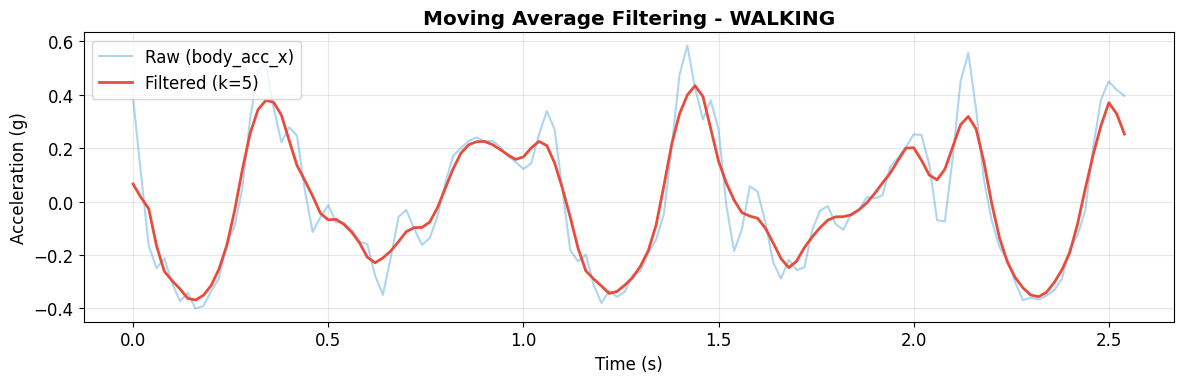

In [10]:
# Visualize filtering on one WALKING window
walk_idx = np.where(labels_train == 'WALKING')[0][5]
t_w = np.arange(WINDOW_SIZE) / 50.0

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t_w, X_train.data[walk_idx, :, 0], alpha=0.4, label='Raw (body_acc_x)', color='#3498db')
ax.plot(t_w, X_train_filtered.data[walk_idx, :, 0], linewidth=2, label='Filtered (k=5)', color='#e74c3c')
ax.set_title('Moving Average Filtering - WALKING', fontweight='bold')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Acceleration (g)')
ax.legend()
plt.tight_layout()
plt.show()

---
## 9. Feature Engineering with tensorts

### 9.1 Time-Domain Features

The original notebook manually loops over windows and channels. With tensorts, `make_statistical_extractor` handles this in one call.

In [11]:
# Time-domain features: mean, std, rms, skew, kurtosis, zcr, iqr
EPS = 1e-10  # for numerical stability
def mean(x): return np.mean(x)
def std(x): return np.std(x)
def rms(x): return np.sqrt(np.mean(np.square(x)))
def skew(x): return np.mean(((x - np.mean(x)) / (np.std(x) + EPS)) ** 3)
def kurtosis(x): return np.mean(((x - np.mean(x)) / (np.std(x) + EPS)) ** 4)
def zcr(x): return np.asarray(np.mean(np.abs(np.diff(np.sign(x)))) / 2)
def iqr(x): return np.percentile(x, 75) - np.percentile(x, 25)

time_fe = FeatureExtractor(
    functions=[('mean', mean), ('std', std), ('rms', rms), ('skew', skew), ('kurtosis', kurtosis), ('zcr', zcr), ('iqr', iqr)],
    input_dim=Dim.TIME,
    scope=Scope.PER_CHANNEL,
)
# or equivelantly: # time_fe = make_statistical_extractor(['mean', 'std', 'rms', 'skew', 'kurtosis', 'zcr', 'iqr'])

X_time_feats = time_fe.fit_transform(X_train_filtered)
print(f"Time features shape: {X_time_feats.shape}")
print(f"  = {X_time_feats.shape[1]} features x {X_time_feats.shape[2]} channels")
print(f"Feature names: {time_fe.feature_names_out_}")

Time features shape: (7352, 7, 6)
  = 7 features x 6 channels
Feature names: ['mean', 'std', 'rms', 'skew', 'kurtosis', 'zcr', 'iqr']


### 9.2 Frequency-Domain Features

Custom spectral features via `FeatureExtractor` in multi-fn mode.

In [12]:
FS = 50.0

def dominant_freq(x):
    freqs = np.fft.rfftfreq(len(x), d=1/FS)
    fft_mag = np.abs(np.fft.rfft(x))
    return float(freqs[np.argmax(fft_mag[1:]) + 1])

def spectral_energy(x):
    fft_mag = np.abs(np.fft.rfft(x))
    return float(np.sum(fft_mag**2) / len(x))

def spectral_entropy(x):
    fft_mag = np.abs(np.fft.rfft(x))
    psd = fft_mag**2
    psd_norm = psd / (np.sum(psd) + 1e-10)
    return float(-np.sum(psd_norm * np.log2(psd_norm + 1e-10)))

def mean_freq(x):
    freqs = np.fft.rfftfreq(len(x), d=1/FS)
    fft_mag = np.abs(np.fft.rfft(x))
    return float(np.sum(freqs * fft_mag) / (np.sum(fft_mag) + 1e-10))


freq_fe = FeatureExtractor(
    functions=[
        ('dom_freq',      dominant_freq),
        ('spec_energy',   spectral_energy),
        ('spec_entropy',  spectral_entropy),
        ('mean_freq',     mean_freq),
    ],
    input_dim=Dim.TIME,
    scope=Scope.PER_CHANNEL
)

X_freq_feats = freq_fe.fit_transform(X_train_filtered)
print(f"Dim Schema: {X_freq_feats.schema}")
print(f"Freq features shape: {X_freq_feats.shape}")
print(f"  = {X_freq_feats.shape[1]} features x {X_freq_feats.shape[2]} channels")
print(f"Feature names: {freq_fe.feature_names_out_}")

Dim Schema: DimSchema(BATCH, FEATURE, CHANNEL)
Freq features shape: (7352, 4, 6)
  = 4 features x 6 channels
Feature names: ['dom_freq', 'spec_energy', 'spec_entropy', 'mean_freq']


### 9.3 Cross-Channel Features (SMA, Acceleration Magnitude)

These operate on multiple channels at once, so we use `FeatureExtractor` with `PER_SAMPLE` scope.

In [13]:
def sma(x, ch_start, ch_end): return float(np.mean(np.sum(np.abs(x[:, ch_start:ch_end]), axis=1)))  # body acc SMA
def mag(x, ch_start, ch_end): return np.linalg.norm(x[:, ch_start:ch_end], axis=1)
def mean_mag(x, ch_start, ch_end): return np.mean(mag(x, ch_start, ch_end))
def std_mag(x, ch_start, ch_end): return np.std(mag(x, ch_start, ch_end))

In [14]:
def cross_channel_features(x):
    """Compute cross-channel features from (T, C) matrix.
    Returns a 1D array of 4 features."""
    sma_acc  = float(np.mean(np.sum(np.abs(x[:, 0:3]), axis=1)))  # body acc SMA
    sma_gyro = float(np.mean(np.sum(np.abs(x[:, 3:6]), axis=1)))  # gyro SMA
    acc_mag  = np.linalg.norm(x[:, 0:3], axis=1)
    return np.array([sma_acc, sma_gyro, np.mean(acc_mag), np.std(acc_mag)])


# cross_fe = FeatureExtractor(
#     fn=cross_channel_features,
#     input_dim=Dim.TIME,
#     # output_dims=(Dim.FEATURE,),
#     scope=Scope.PER_SAMPLE,
#     name='cross_channel',
# )

In [15]:
cross_fe = FeatureExtractor(
    functions=[
        ('sma_acc', sma, {"ch_start": 0, "ch_end": 3}), 
        ('sma_gyr', sma, {"ch_start": 3, "ch_end": 6}), 
        ('mean_mag', mean_mag, {"ch_start": 0, "ch_end": 3}),
        ('std_mag', std_mag, {"ch_start": 0, "ch_end": 3})
    ],
    input_dim=Dim.TIME,
    scope=Scope.PER_SAMPLE
)
# print("Cross-channel features: sma_bacc, sma_gyro, acc_mag_mean, acc_mag_std")
# Test cross-channel features on training data
X_cross = cross_fe.fit_transform(X_train_filtered)
print(f"Cross-channel feature shape: {X_cross.shape}")
print(f"  = (n_windows, 4 features) — sma_acc, sma_gyro, acc_mag_mean, acc_mag_std")
print(f"  channels: {list(X_cross.channels.names)}")
print(f"\nSample values (first window):")
feat_names = list(X_cross.channels.names)
for name, val in zip(feat_names, X_cross.data[0]):
    print(f"  {name}: {val:.4f}")

Cross-channel feature shape: (7352, 4)
  = (n_windows, 4 features) — sma_acc, sma_gyro, acc_mag_mean, acc_mag_std
  channels: ['sma_acc', 'sma_gyr', 'mean_mag', 'std_mag']

Sample values (first window):
  sma_acc: 0.0224
  sma_gyr: 0.0517
  mean_mag: 0.0174
  std_mag: 0.0102


---
## 10. Full tensorts Pipeline

Here's the key payoff: **one pipeline** replaces all manual loops. The pipeline handles filtering, label encoding, scaling, feature extraction, and flattening.

In [16]:
from tensorts import FeatureUnion

In [17]:
preprocessing = Pipeline([
    ('label_enc', LabelEncoder()),
    ('filter',    FunctionTransform(fn=moving_average, scope=Scope.PER_CHANNEL, fn_kwargs={'k': 5}, name='moving_avg')),
    ('scaler',    StandardScaler()),
    ('features',  FeatureUnion([
        ('stats', make_statistical_extractor(['mean', 'std', 'rms', 'skew', 'kurtosis', 'zcr', 'iqr'])),
        ('freq',  FeatureExtractor(functions=[('dom_freq', dominant_freq), ('spec_energy', spectral_energy), ('spec_entropy', spectral_entropy), ('mean_freq', mean_freq)])),
        ('cross', FeatureExtractor(fn=cross_channel_features, scope=Scope.PER_SAMPLE, name='cross')),
      ])),
    # ('flat', Flatten())
  ])

# Fit on train, transform both
Xt_train = preprocessing.fit_transform(X_train)
Xt_test  = preprocessing.transform(X_test)

In [18]:
print(f"Pipeline output (train): {Xt_train.shape}")
print(f"Pipeline output (test):  {Xt_test.shape}")
print(f"Labels encoded: {np.unique(Xt_train.y)}")
print(f"Label classes: {preprocessing['label_enc'].classes_}")
print(f"\nScaler mean shape: {preprocessing['scaler'].mean_.shape}")
print(f"Features per window: {Xt_train.shape[1]}")
n_stats = 15 # len(preprocessing["features"].feature_names_out_) --> think if it makes sense to cross product all the sub-extractors' feature names -> probably not because how would nested features in a single function would be calculated?
n_channels = len(X_train.channels.names)
print(f"  = {n_stats} stats x {n_channels} channels = {n_stats * n_channels}")

Pipeline output (train): (7352, 70)
Pipeline output (test):  (2947, 70)
Labels encoded: [0 1 2 3 4 5]
Label classes: ['LAYING' 'SITTING' 'STANDING' 'WALKING' 'WALKING_DOWNSTAIRS'
 'WALKING_UPSTAIRS']

Scaler mean shape: (1, 6)
Features per window: 70
  = 15 stats x 6 channels = 90


---
## 11. EDA: Feature Distributions

In [19]:
# Build a DataFrame for exploration
le = preprocessing['label_enc']
idx2label = {v: k for k, v in le._class_to_idx.items()}
y_train_str = np.array([idx2label[i] for i in Xt_train.y])

col_names = Xt_test.channels.names

df_explore = pd.DataFrame(Xt_train.data, columns=col_names[:Xt_train.shape[1]])
df_explore['activity'] = y_train_str

---
## 12. ANOVA Feature Ranking

In [20]:
F_scores, p_values = f_classif(Xt_train.data, Xt_train.y)

feat_ranking = pd.DataFrame({
    'Feature': col_names[:Xt_train.shape[1]],
    'F_score': F_scores,
    'p_value': p_values,
}).sort_values('F_score', ascending=False).reset_index(drop=True)

print(f"Total features: {len(feat_ranking)}")
print(f"\nTop 10 most discriminative:")
print(feat_ranking.head(10).to_string(index=False))
print(f"\nBottom 5 least discriminative:")
print(feat_ranking.tail(5).to_string(index=False))

Total features: 70

Top 10 most discriminative:
         Feature      F_score  p_value
 std__body_acc_x 15367.913999      0.0
 rms__body_acc_x 14623.735635      0.0
         cross_0 12324.704357      0.0
         cross_2 11223.655791      0.0
 std__body_acc_y  9768.920067      0.0
 iqr__body_acc_x  8629.406562      0.0
         cross_1  7942.237933      0.0
 iqr__body_acc_y  7014.853401      0.0
 rms__body_acc_y  6475.600033      0.0
rms__body_gyro_x  6455.868079      0.0

Bottom 5 least discriminative:
              Feature   F_score      p_value
dom_freq__body_gyro_x 32.477380 7.191885e-33
    mean__body_gyro_y 24.919705 5.475612e-25
     mean__body_acc_x 16.104427 7.995780e-16
     mean__body_acc_y 15.307702 5.331788e-15
     mean__body_acc_z 11.376510 5.900160e-11


In [21]:
list(feat_ranking.loc[:9, "Feature"].values)

['std__body_acc_x',
 'rms__body_acc_x',
 'cross_0',
 'cross_2',
 'std__body_acc_y',
 'iqr__body_acc_x',
 'cross_1',
 'iqr__body_acc_y',
 'rms__body_acc_y',
 'rms__body_gyro_x']

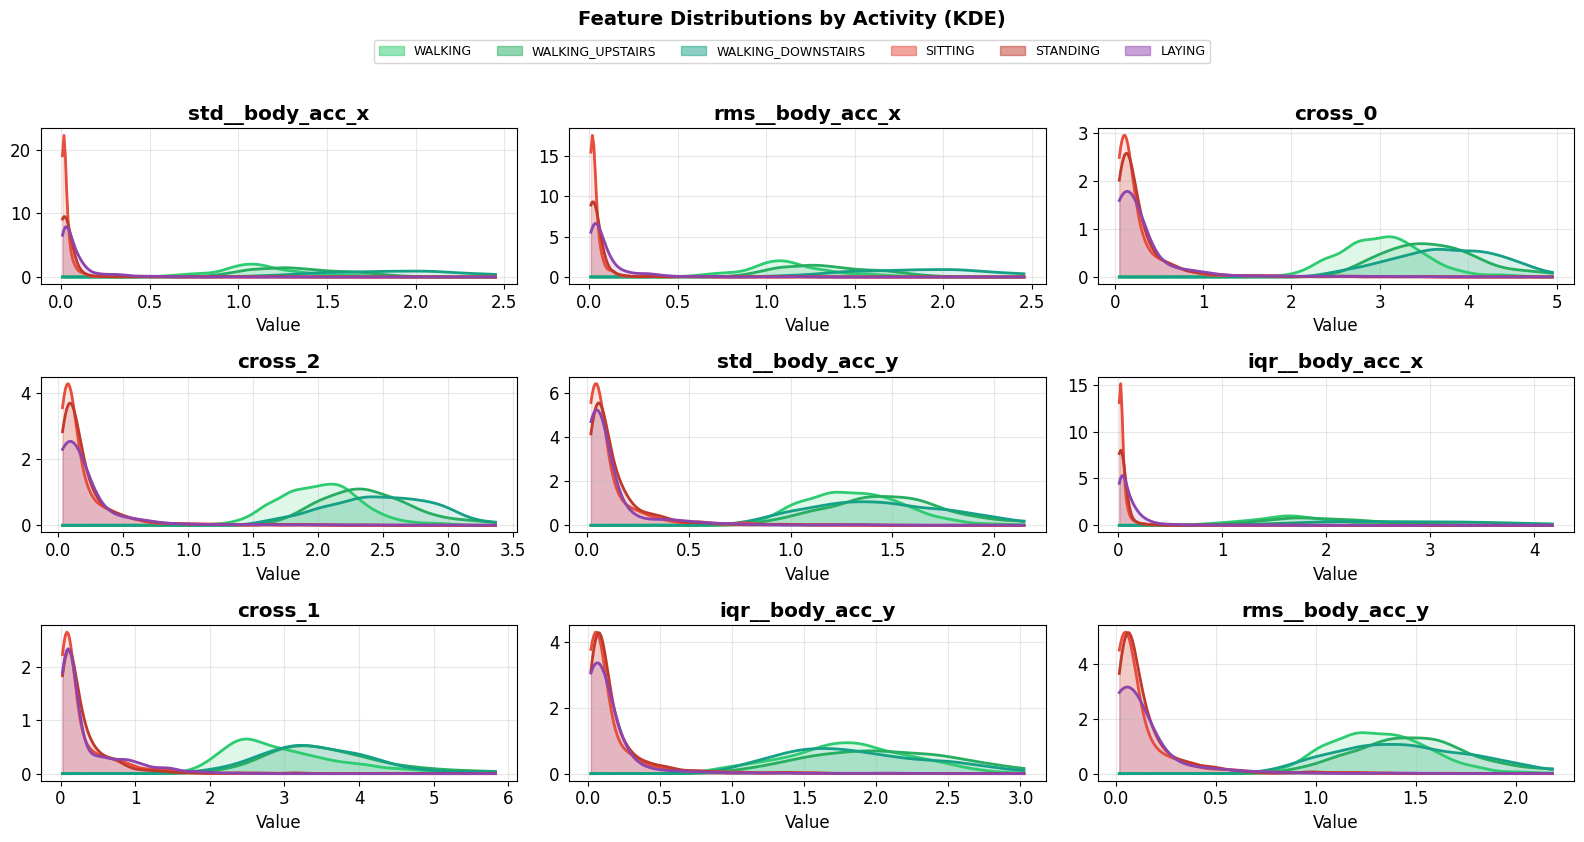

In [22]:
# Pick key features for visualization
top_n = 9
key_features = list(feat_ranking.loc[:top_n-1, "Feature"].values)

fig, axes = plt.subplots(3, 3, figsize=(16, 8))
for ax, feat in zip(axes.flat, key_features):
    all_vals = df_explore[feat].dropna()
    x_min, x_max = all_vals.quantile(0.01), all_vals.quantile(0.99)
    x_grid = np.linspace(x_min, x_max, 300)
    for act in ACTIVITY_COLORS:
        subset = df_explore.loc[df_explore['activity'] == act, feat].dropna().values
        if len(subset) < 5:
            continue
        kde = gaussian_kde(subset, bw_method='scott')
        density = kde(x_grid)
        ax.plot(x_grid, density, color=ACTIVITY_COLORS[act], lw=2, label=act)
        ax.fill_between(x_grid, density, alpha=0.15, color=ACTIVITY_COLORS[act])
    ax.set_title(feat, fontweight='bold')
    ax.set_xlabel('Value')

handles = [mpatches.Patch(color=ACTIVITY_COLORS[a], label=a, alpha=0.5) for a in ACTIVITY_COLORS]
fig.legend(handles=handles, loc='upper center', ncol=6, fontsize=9, bbox_to_anchor=(0.5, 1.02))
fig.suptitle('Feature Distributions by Activity (KDE)', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

---
## 13. Correlation Heatmap

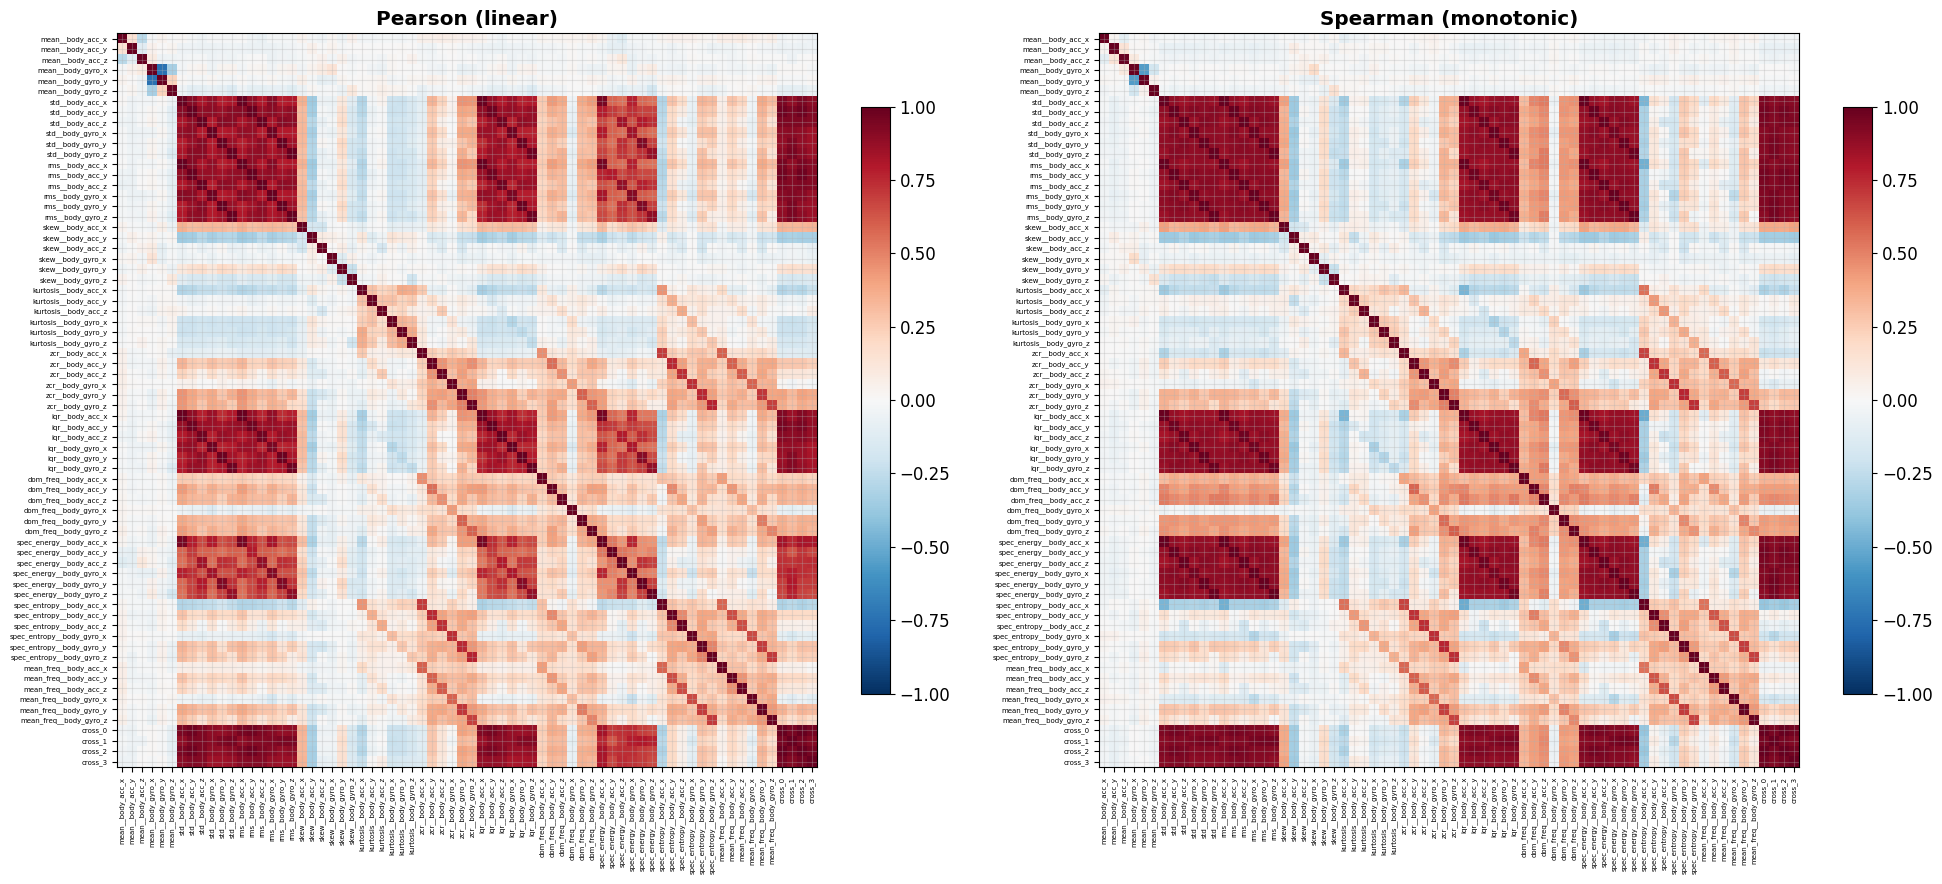

Highly correlated pairs |r| > 0.9: 81
  rms__body_acc_x                     <-> std__body_acc_x                      r = +0.999
  cross_2                             <-> cross_0                              r = +0.999
  rms__body_gyro_y                    <-> std__body_gyro_y                     r = +0.998
  rms__body_acc_z                     <-> std__body_acc_z                      r = +0.992
  rms__body_gyro_z                    <-> std__body_gyro_z                     r = +0.990
  rms__body_acc_y                     <-> std__body_acc_y                      r = +0.987
  iqr__body_acc_x                     <-> std__body_acc_x                      r = +0.985
  iqr__body_acc_x                     <-> rms__body_acc_x                      r = +0.985
  iqr__body_gyro_y                    <-> std__body_gyro_y                     r = +0.980
  iqr__body_gyro_y                    <-> rms__body_gyro_y                     r = +0.977


In [23]:
X_train_df = pd.DataFrame(Xt_train.data, columns=col_names[:Xt_train.shape[1]])

fig, axes = plt.subplots(1, 2, figsize=(20, 9))

for ax, method, title in zip(axes, ['pearson', 'spearman'],
                              ['Pearson (linear)', 'Spearman (monotonic)']):
    corr = X_train_df.corr(method=method)
    im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=90, fontsize=5)
    ax.set_yticklabels(corr.columns, fontsize=5)
    ax.set_title(title, fontweight='bold')
    plt.colorbar(im, ax=ax, shrink=0.8)

plt.tight_layout()
plt.show()

# Highly correlated pairs
corr_p = X_train_df.corr(method='pearson')
upper = corr_p.where(np.triu(np.ones(corr_p.shape), k=1).astype(bool))
high_corr = [(upper.columns[j], upper.index[i], upper.iloc[i, j])
             for i in range(len(upper)) for j in range(len(upper.columns))
             if abs(upper.iloc[i, j]) > 0.9]
print(f"Highly correlated pairs |r| > 0.9: {len(high_corr)}")
for f1, f2, r in sorted(high_corr, key=lambda x: -abs(x[2]))[:10]:
    print(f"  {f1:35s} <-> {f2:35s}  r = {r:+.3f}")

---
## 14. PCA Visualization (via tensorts)

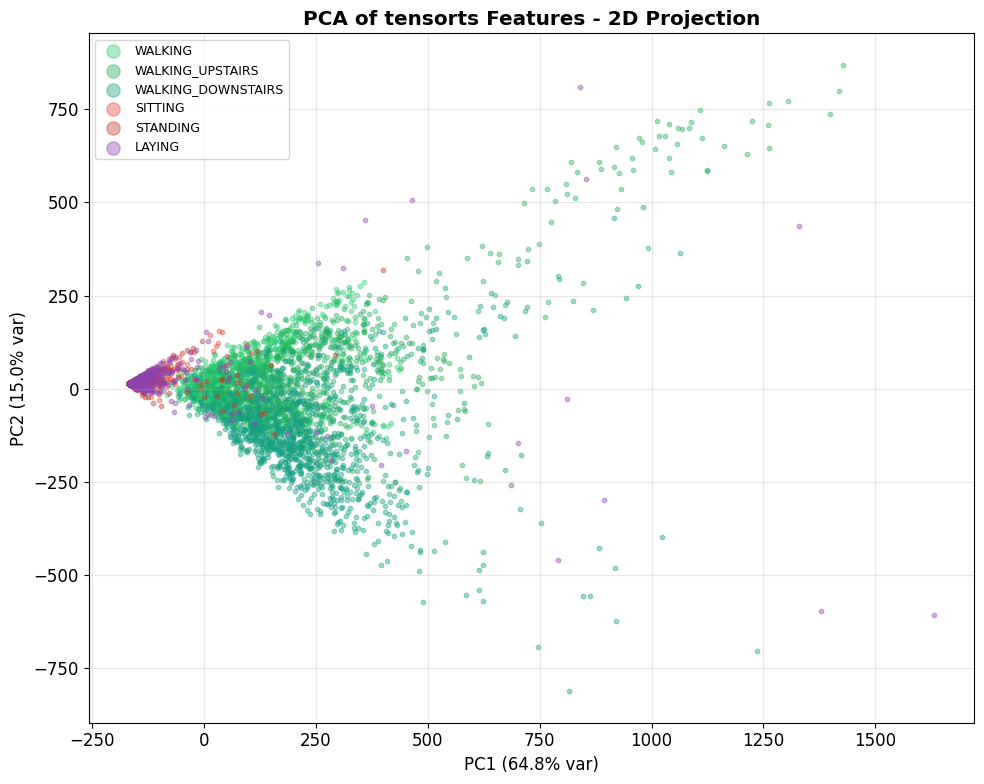

Variance explained by 3 PCs: 89.7%


In [24]:
pca_pipe = Pipeline([
    ('label_enc', LabelEncoder()),
    ('filter',    FunctionTransform(fn=moving_average, scope=Scope.PER_CHANNEL, fn_kwargs={'k': 5}, name='moving_avg')),
    ('scaler',    StandardScaler()),
    ('features',  FeatureUnion([
        ('stats', make_statistical_extractor(['mean', 'std', 'rms', 'skew', 'kurtosis', 'zcr', 'iqr'])),
        ('freq',  FeatureExtractor(functions=[('dom_freq', dominant_freq), ('spec_energy', spectral_energy), ('spec_entropy', spectral_entropy), ('mean_freq', mean_freq)])),
        ('cross', FeatureExtractor(fn=cross_channel_features, scope=Scope.PER_SAMPLE, name='cross')),
      ])),
    ('flat', Flatten()),
    ('pca', PCA())
])
# from sklearn.decomposition import PCA

# pca_pipe = SklearnWrapper(_pca_pipe, PCA(n_components=3))

X_pca = pca_pipe.fit_transform(X_train)
pca_step = pca_pipe['pca']

fig, ax = plt.subplots(figsize=(10, 8))
for act in ACTIVITY_COLORS:
    act_idx = le._class_to_idx.get(act)
    if act_idx is None:
        continue
    mask = X_pca.y == act_idx
    ax.scatter(X_pca.data[mask, 0], X_pca.data[mask, 1],
               s=10, alpha=0.4, color=ACTIVITY_COLORS[act], label=act)

evr = pca_step.explained_variance_ / pca_step.explained_variance_.sum()
ax.set_xlabel(f'PC1 ({evr[0]*100:.1f}% var)')
ax.set_ylabel(f'PC2 ({evr[1]*100:.1f}% var)')
ax.set_title('PCA of tensorts Features - 2D Projection', fontweight='bold')
ax.legend(markerscale=3, fontsize=9)
plt.tight_layout()
plt.show()

print(f"Variance explained by 3 PCs: {evr[:3].sum()*100:.1f}%")

---
## 15. Classification with SklearnWrapper

### 15.1 Logistic Regression

In [25]:
# Reuse the preprocessing pipeline from Section 10
y_train_enc = Xt_train.y
y_test_enc  = Xt_test.y

X_train_np = Xt_train.data
X_test_np  = Xt_test.data

print(f"Train: {X_train_np.shape}, Test: {X_test_np.shape}")
print(f"Classes: {le.classes_}")

Train: (7352, 70), Test: (2947, 70)
Classes: ['LAYING' 'SITTING' 'STANDING' 'WALKING' 'WALKING_DOWNSTAIRS'
 'WALKING_UPSTAIRS']


### 15.3 Random Forest

In [26]:
rf = RandomForestClassifier(n_estimators=200, max_depth=20, max_features='sqrt',
                             min_samples_leaf=2, random_state=SEED, n_jobs=-1)
rf.fit(X_train_np, y_train_enc)
y_pred_rf = rf.predict(X_test_np)

acc_rf = accuracy_score(y_test_enc, y_pred_rf)
f1_rf  = f1_score(y_test_enc, y_pred_rf, average='macro')

print('=== Random Forest ===')
print(f'Accuracy:   {acc_rf:.4f}')
print(f'F1 (macro): {f1_rf:.4f}')

=== Random Forest ===
Accuracy:   0.8924
F1 (macro): 0.8930


### 15.4 SklearnWrapper + GridSearchCV

This is where tensorts shines: **tune pipeline hyperparameters and estimator hyperparameters together** using sklearn's `GridSearchCV`.

In [27]:
# Build a fresh pipeline for the wrapper
pipe_for_cv = Pipeline([
    ('label_enc', LabelEncoder()),
    ('filter',    FunctionTransform(fn=moving_average, scope=Scope.PER_CHANNEL, fn_kwargs={'k': 5}, name='moving_avg')),
    ('scaler',    StandardScaler()),
    ('features',  FeatureUnion([
        ('stats', make_statistical_extractor(['mean', 'std', 'rms', 'skew', 'kurtosis', 'zcr', 'iqr'])),
        ('freq',  FeatureExtractor(functions=[('dom_freq', dominant_freq), ('spec_energy', spectral_energy), ('spec_entropy', spectral_entropy), ('mean_freq', mean_freq)])),
        ('cross', FeatureExtractor(fn=cross_channel_features, scope=Scope.PER_SAMPLE, name='cross')),
      ])),
    ('flat', Flatten()),
    # ('pca', PCA())
])

wrapper = SklearnWrapper(pipe_for_cv, RandomForestClassifier(random_state=SEED, n_jobs=-1))

# Cross-validate
scores = cross_val_score(wrapper, X_train, y=X_train.y, cv=StratifiedKFold(5), scoring='accuracy')
print(f"5-Fold CV Accuracy: {scores.mean():.4f} +/- {scores.std():.4f}")
print(f"Per-fold: {scores}")

5-Fold CV Accuracy: 0.8498 +/- 0.0352
Per-fold: [0.80081577 0.82460911 0.86666667 0.8537415  0.90340136]


In [28]:
# GridSearchCV: tune estimator hyperparameters through the wrapper
param_grid = {
    'estimator__n_estimators': [100, 200],
    'estimator__max_depth': [15, 20, None],
}

gs = GridSearchCV(wrapper, param_grid, cv=3, scoring='accuracy', n_jobs=1)
gs.fit(X_train, y=X_train.y)

print(f"Best params: {gs.best_params_}")
print(f"Best CV accuracy: {gs.best_score_:.4f}")

Best params: {'estimator__max_depth': 20, 'estimator__n_estimators': 200}
Best CV accuracy: 0.8454


---
## 16. Confusion Matrices

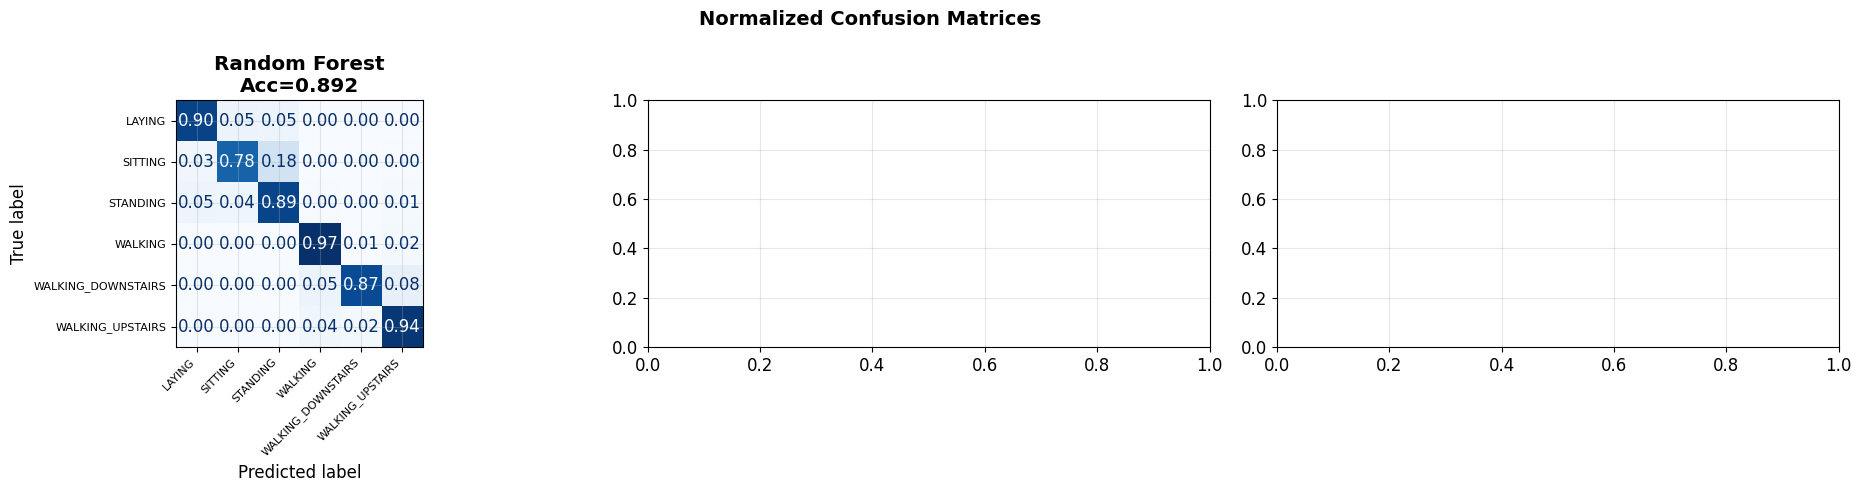

In [29]:
all_models = {
    # 'Logistic Regression': y_pred_lr,
    # 'SVM (Linear)': y_pred_svm,
    'Random Forest': y_pred_rf,
}

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (name, preds) in zip(axes, all_models.items()):
    cm_n = confusion_matrix(y_test_enc, preds, normalize='true')
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_n, display_labels=le.classes_)
    disp.plot(cmap='Blues', ax=ax, values_format='.2f', colorbar=False)
    acc = accuracy_score(y_test_enc, preds)
    ax.set_title(f'{name}\nAcc={acc:.3f}', fontweight='bold')
    plt.sca(ax)
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.yticks(fontsize=8)

fig.suptitle('Normalized Confusion Matrices', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [30]:
pipe = Pipeline([                                                                                                                                                                                    
    ('label_enc', LabelEncoder()),
    ('filter',    FunctionTransform(fn=moving_average, scope=Scope.PER_CHANNEL, fn_kwargs={'k': 5}, name='moving_avg')),
    ('scaler',    StandardScaler()),
    ('window',    SlidingWindow(size=10, stride=5, flatten_batch=False)),
    # Extracts stats over each 5-step window, per channel                                                                                                                                            
    ('features',  FeatureUnion([
        ('stats', make_statistical_extractor(['mean', 'std', 'rms', 'skew', 'kurtosis', 'zcr', 'iqr'])),
        ('freq',  FeatureExtractor(
            functions=[('dom_freq', dominant_freq), ('spec_energy', spectral_energy), ('spec_entropy', spectral_entropy), ('mean_freq', mean_freq)],
            input_dim=Dim.TIME, scope=Scope.PER_CHANNEL
            )),
        ('cross', FeatureExtractor(fn=cross_channel_features, scope=Scope.PER_SAMPLE, name='cross')),
      ])),                                                                                                                                                                             
  ])                                                                                                                                                                    

In [32]:
X_train_temporal = pipe.fit_transform(X_train)
X_test_temporal = pipe.transform(X_test)

X_train_temporal.shape, X_test_temporal.shape

((7352, 24, 70), (2947, 24, 70))

In [34]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

In [45]:
# PyTorch Conv1d expects (batch, channels, time)
X_train_rolling = torch.FloatTensor(X_train_temporal.numpy()).permute(0, 2, 1)
X_test_rollin  = torch.FloatTensor(X_test_temporal.numpy()).permute(0, 2, 1)
y_train_r      = torch.LongTensor(X_train_temporal.y)
y_test_r       = torch.LongTensor(X_test_temporal.y)

cnn_train_loader = DataLoader(TensorDataset(X_train_rolling, y_train_r), batch_size=64, shuffle=True)
cnn_test_loader  = DataLoader(TensorDataset(X_test_rollin, y_test_r), batch_size=64)

---
## 19. Deep Learning: 1D CNN on Raw Windows

The CNN operates on the raw windowed data. We use tensorts' `StandardScaler` to standardize per-channel, then extract numpy for PyTorch.

In [46]:
device = torch.device('mps' if torch.backends.mps.is_available() else
                      'cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

n_classes = len(le.classes_)


def train_model(model, train_loader, test_loader, n_epochs=30, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)
    history = {'train_loss': [], 'train_acc': [], 'test_acc': []}

    for epoch in range(n_epochs):
        model.train()
        epoch_loss, correct, total = 0, 0, 0
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            out = model(X_b)
            loss = criterion(out, y_b)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            correct += (out.argmax(1) == y_b).sum().item()
            total += len(y_b)
        scheduler.step()

        model.eval()
        test_correct, test_total = 0, 0
        with torch.no_grad():
            for X_b, y_b in test_loader:
                X_b, y_b = X_b.to(device), y_b.to(device)
                out = model(X_b)
                test_correct += (out.argmax(1) == y_b).sum().item()
                test_total += len(y_b)

        history['train_loss'].append(epoch_loss / len(train_loader))
        history['train_acc'].append(correct / total)
        history['test_acc'].append(test_correct / test_total)

        if (epoch + 1) % 10 == 0:
            print(f"  Epoch {epoch+1:3d}/{n_epochs} | "
                  f"Loss: {history['train_loss'][-1]:.4f} | "
                  f"Train: {history['train_acc'][-1]:.4f} | "
                  f"Test: {history['test_acc'][-1]:.4f}")
    return history


def evaluate_model(model, test_loader):
    model.eval()
    all_preds, all_true = [], []
    with torch.no_grad():
        for X_b, y_b in test_loader:
            out = model(X_b.to(device))
            all_preds.extend(out.argmax(1).cpu().numpy())
            all_true.extend(y_b.numpy())
    return np.array(all_true), np.array(all_preds)

Device: mps


In [47]:
X_train_rolling.shape

torch.Size([7352, 70, 24])

In [50]:
n_channels = X_train_rolling.shape[1]
seq_len    = X_train_rolling.shape[2]
print(f"CNN input: ({n_channels} channels, {seq_len} timesteps)")

CNN input: (70 channels, 24 timesteps)


In [51]:
class CNN1D(nn.Module):
    def __init__(self, n_channels=6, n_classes=6):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(n_channels, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm1d(256), nn.ReLU(), nn.AdaptiveAvgPool1d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(256, 128), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(128, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


cnn = CNN1D(n_channels=n_channels, n_classes=n_classes)
print(f'Parameters: {sum(p.numel() for p in cnn.parameters()):,}')
print("\nTraining CNN...")
cnn_history = train_model(cnn, cnn_train_loader, cnn_test_loader, n_epochs=50)

Parameters: 205,638

Training CNN...
  Epoch  10/50 | Loss: 0.1770 | Train: 0.9347 | Test: 0.8140
  Epoch  20/50 | Loss: 0.0343 | Train: 0.9882 | Test: 0.8795
  Epoch  30/50 | Loss: 0.0151 | Train: 0.9948 | Test: 0.8839
  Epoch  40/50 | Loss: 0.0050 | Train: 0.9985 | Test: 0.8799
  Epoch  50/50 | Loss: 0.0029 | Train: 0.9992 | Test: 0.8731


In [52]:
y_true_cnn, y_pred_cnn = evaluate_model(cnn, cnn_test_loader)
acc_cnn = accuracy_score(y_true_cnn, y_pred_cnn)
f1_cnn  = f1_score(y_true_cnn, y_pred_cnn, average='macro')

print(f'=== 1D CNN (raw windows) ===')
print(f'Accuracy:   {acc_cnn:.4f}')
print(f'F1 (macro): {f1_cnn:.4f}')
print(classification_report(y_true_cnn, y_pred_cnn, target_names=le.classes_))

=== 1D CNN (raw windows) ===
Accuracy:   0.8731
F1 (macro): 0.8788
                    precision    recall  f1-score   support

            LAYING       0.88      0.75      0.81       555
           SITTING       0.70      0.75      0.73       491
          STANDING       0.77      0.84      0.80       523
           WALKING       1.00      0.99      0.99       496
WALKING_DOWNSTAIRS       0.95      0.99      0.97       427
  WALKING_UPSTAIRS       0.98      0.96      0.97       455

          accuracy                           0.87      2947
         macro avg       0.88      0.88      0.88      2947
      weighted avg       0.88      0.87      0.87      2947



---
## 24. Save the Best Model with joblib

In [ ]:
import joblib

pipe_to_deploy = Pipeline([
    ('label_enc', LabelEncoder()),
    ('filter',    FunctionTransform(fn=moving_average, scope=Scope.PER_CHANNEL, fn_kwargs={'k': 5}, name='moving_avg')),
    ('scaler',    StandardScaler()),
    ('features',  FeatureUnion([
        ('stats', make_statistical_extractor(['mean', 'std', 'rms', 'skew', 'kurtosis', 'zcr', 'iqr'])),
        ('freq',  FeatureExtractor(functions=[('dom_freq', dominant_freq), ('spec_energy', spectral_energy), ('spec_entropy', spectral_entropy), ('mean_freq', mean_freq)])),
        ('cross', FeatureExtractor(fn=cross_channel_features, scope=Scope.PER_SAMPLE, name='cross')),
      ])),
    ('flat', Flatten()),
])

# Refit the wrapper on full training data with best RF
final_pipe_to_deploy = SklearnWrapper(
    pipe_to_deploy,
    RandomForestClassifier(n_estimators=200, max_depth=20, random_state=SEED, n_jobs=-1)
)

final_pipe_to_deploy.fit(X_train, y=X_train.y)

# Save
joblib.dump(final_pipe_to_deploy, 'har_model.joblib')
print(f"Model saved: {os.path.getsize('har_model.joblib') / 1024:.0f} KB")

# Load and verify
wrapper_loaded = joblib.load('har_model.joblib')
preds_loaded = wrapper_loaded.predict(X_test)
print(f"Loaded model accuracy: {accuracy_score(y_test_labels, preds_loaded):.4f}")

Model saved: 29676 KB
Loaded model accuracy: 0.8867


---
## Summary

**What tensorts replaced:**

| Original (manual) | tensorts equivalent |
|---|---|
| Per-window, per-channel filter loop | `FunctionTransform(moving_average, scope=PER_CHANNEL)` |
| Manual `StandardScaler` on flattened arrays | `StandardScaler()` (channel-aware, no reshape needed) |
| Manual feature extraction loops (42 lines) | `make_statistical_extractor([...])` (1 line) |
| Custom FFT feature functions per channel | `FeatureExtractor(functions=[...])` |
| `sklearn.LabelEncoder` on separate array | `LabelEncoder()` in pipeline (labels travel with data) |
| Manual flatten + reshape | `Flatten()` |
| Separate scaling for CNN input | `StandardScaler()` (same API, per-channel) |
| Manual `Pipeline` assembly for GridSearchCV | `SklearnWrapper` with nested `get_params`/`set_params` |

**Key benefits:**
- Channel names, labels, and metadata propagate through the entire pipeline
- No index bugs: transforms resolve axes by semantic name (`Dim.TIME`, `Dim.CHANNEL`)
- One `fit_transform` / `transform` call replaces dozens of manual loops
- Full sklearn compatibility for CV, GridSearchCV, and model persistence